In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seabornInstance
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
DB_CONFIG = {
    'drivername': 'mysql+pymysql',
    'host': 'localhost',
    'database': 'retail',
    'username': 'root',
    'password': 'ishak@177'
}
connection_url = URL.create(**DB_CONFIG)
engine = create_engine(connection_url)
orders_df = pd.read_sql('SELECT * FROM orders', engine)
order_items_df = pd.read_sql('SELECT * FROM order_items', engine)
customers_df = pd.read_sql('SELECT * FROM customers', engine)
print("Data loaded successfully!")
print("Orders shape:", orders_df.shape)
print("Order Items shape:", order_items_df.shape)
print("Customers shape:", customers_df.shape)

Data loaded successfully!
Orders shape: (1615, 8)
Order Items shape: (4722, 8)
Customers shape: (195, 9)


<class 'pandas.DataFrame'>
RangeIndex: 1615 entries, 0 to 1614
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   order_id       1615 non-null   int64
 1   customer_id    1615 non-null   int64
 2   order_status   1615 non-null   str  
 3   order_date     1615 non-null   str  
 4   required_date  1615 non-null   str  
 5   shipped_date   1615 non-null   str  
 6   store_id       1615 non-null   int64
 7   staff_id       1615 non-null   int64
dtypes: int64(4), str(4)
memory usage: 101.1 KB
None
          order_id      item_id   product_id     quantity    list_price  \
count  4722.000000  4722.000000  4722.000000  4722.000000   4722.000000   
mean    821.265354     2.262601    59.366158     1.498941   1212.717069   
std     465.152168     1.199129    67.312708     0.500052   1352.798489   
min       1.000000     1.000000     2.000000     1.000000     90.000000   
25%     423.250000     1.000000    14.000000     1.000000

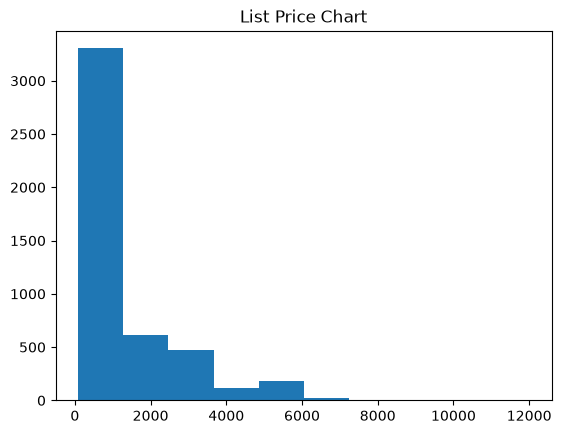

In [9]:
print(orders_df.info())
print(order_items_df.describe())
print(orders_df['order_status'].value_counts())
plt.hist(order_items_df['list_price'])
plt.title("List Price Chart")
plt.show()

In [10]:
orders_df['order_date'] = pd.to_datetime(orders_df['order_date'])
df = pd.merge(orders_df, order_items_df, on='order_id')
last_date = df['order_date'].max()
rfm = df.groupby('customer_id').agg({
    'order_date': lambda x: (last_date - x.max()).days, 
    'order_id': 'nunique', 
    'total_price': 'sum'
})
rfm.columns = ['recency', 'frequency', 'monetary']
rfm = rfm.reset_index()
print(rfm.head())

   customer_id  recency  frequency  monetary
0            1       40          3     30646
1            2      263          3     21654
2            3       68          3     26250
3            4      254          3     24199
4            5      255          3     19443


In [5]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
x = rfm[['recency', 'frequency', 'monetary']]
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
model = KMeans(n_clusters=3, random_state=42)
rfm['segment'] = model.fit_predict(x_scaled)
print(rfm.head())

   customer_id  recency  frequency  monetary  segment
0            1       40          3     30646        2
1            2      263          3     21654        2
2            3       68          3     26250        2
3            4      254          3     24199        2
4            5      255          3     19443        2


In [6]:
rfm.to_sql('customer_segments', con=engine, if_exists='replace', index=False)

1445